## Import

In [22]:
%reset -f
import tensorflow as tf
import numpy as np
import copy as cp
import scipy.sparse.linalg as linalg
import matplotlib.pyplot as plt
from time import time
import scipy.optimize
import scipy.stats as stats
from mpl_toolkits.mplot3d import Axes3D
from scipy.spatial import KDTree

gpus = tf.config.experimental.list_physical_devices('GPU')
for gpu in gpus:
  tf.config.experimental.set_memory_growth(gpu, True)

## Volumes finis

In [23]:
# Classe résolvant Burgers avec des volumes finis 1D (cours P. Helluy)
class EDP:
    def __init__(self,Nx,viscosity, u_0):
      
        self.Nx=Nx  # nb mailles
        self.a=-1.0  # bord gauche du domaine
        self.b=1.0  # bord droit du domaine
        self.viscosity = viscosity
        self.dt=0.0
        self.u_0 = u_0       

        # Pour le maillage Nx mailles et 2 maillages fantome a gauche et droite pour les conditions limites
        self.h=(self.b-self.a)/self.Nx  # pas de maillage
        self.begin = 1  # numéro de la première maille non fantome
        self.end=  self.Nx+1  # numéro de la dernière maille non fantome  
        
        self.nodes=np.linspace(self.a-self.h,self.b+self.h,self.Nx+3) 
        #listes des noeuds: n+1 noeuds et 2 noeuds fantomes
        self.cells=np.linspace(self.a-0.5*self.h,self.b+0.5*self.h,self.Nx+2)
        #listes des centres de mailles: n centres et 2 centres fantomes
        self.rho= np.zeros(self.Nx+2) ## rho sur le maillage + mailles fantomes
    
    #fonction pour initialiser rho
    def init(self):
    
        for i in range(0,len(self.rho)):
            self.rho[i]=self.u_0(self.cells[i])
    
        # on conserve le rho initiale
        self.rho_0=cp.copy(self.rho)

    # flux volumes finis de Lax-Friedrichs
    def flux_hyp_burgers(self,rl,rr):
        center = 0.5*(0.5*rl*rl+0.5*rr*rr)
        vel = max(abs(rl),abs(rr))
        visco=0.5*vel*(rl-rr)
        return center+visco
        
    # flux volumes finis du terme de diffusion
    def flux_diff(self,rl,rr):
        grad = self.viscosity*(rr-rl)/self.h
        return grad
    
    # plot de rho_0 et de rho
    def plot(self):
        fig, axes = plt.subplots(1, 2, figsize=(12, 4))
        axes[0].plot(self.cells[self.begin:self.end],self.rho_0[self.begin:self.end],'r-')
        axes[1].plot(self.cells[self.begin:self.end],self.rho[self.begin:self.end],'b-')
        
    # condition limite dans les mailles fantomes selon le cas test. A expliquer
    def bc(self):
        self.rho[0]=0
        self.rho[-1]=0
    
    # le terme de diffusion est traité par un schéma implicite en temps
    # le terme de Burgers par un schema implicite
    # Ici on contruit le produit matrice vecteur entre la matrice implicite et un vecteur v
    def matvec_Laplacian(self,v):
        res=np.zeros(self.Nx)
        vl=0.0
        vr=0.0

        res[0]= v[0]-self.dt*self.viscosity/(self.h**2.0)*(vl-2.0*v[0]+v[1])
        for i in range(1,self.Nx-1):
            res[i]= v[i]-self.dt*self.viscosity/(self.h**2.0)*(v[i-1]-2.0*v[i]+v[i+1])
            
        res[-1]= v[-1]-self.dt*self.viscosity/(self.h**2.0)*(v[-2]-2.0*v[-1]+vr)
        return res
        
    # Résolution de l'équation en temps
    # A est un opérateur linéaire associée à la matrice implicite (le produit matrice vecteur)
    # on a pas besoin de construire la matrice pour résoudre un problème avec le gradient conjugé.
    # Il suffit juste de donner ce produit matrice vecteur
    def solve_loc(self,T,flux):
        sol=[]
        nt = 0
        time = 0.0
        rho_temp = np.zeros(self.Nx)
        self.A = linalg.LinearOperator((self.Nx,self.Nx), matvec=self.matvec_Laplacian)
        while time < T:
            # vitesse max de l'équation utile pour CFL
            vmax=max(abs(self.rho[self.begin:self.end]))
            self.dt= 0.5*self.h/vmax
            for i in range(0,self.Nx):
                # calcul des conditions limites dans la mailles fantomes
                self.bc()
                rhol = self.rho[self.begin+i-1]
                rhoc = self.rho[self.begin+i]
                rhor = self.rho[self.begin+i+1]
                # calcul des flux explicite
                fh=flux(rhoc,rhor)-flux(rhol,rhoc)
                # schéma en temps explicite
                rho_temp[i]=rhoc -self.dt/self.h*fh
        
            # schéma en temps implicite en résovlant Arho^{n+1}= Explicit
            self.rho[self.begin:self.end],info=linalg.cg(self.A,rho_temp,x0=None,tol=1e-06,maxiter=200)
            sol.append(cp.copy(self.rho[self.begin:self.end]))
            time=time+self.dt
            nt=nt+1
        return sol
    
    def solve(self,T):
        sol=self.solve_loc(T,self.flux_hyp_burgers)
        return sol

def u_0(x):
  return -np.sin(np.pi*x)

## Paramètres

In [36]:
# Set data type
DTYPE='float32'
tf.keras.backend.set_floatx(DTYPE)

# Set constants
pi = tf.constant(np.pi, dtype=DTYPE)
viscosity = tf.constant(1e-3, dtype=DTYPE)

# Set boundary
tmin = 0.
tmax = 1.
xmin = -1.
xmax = 1.

# Lower bounds
lb = tf.constant([tmin, xmin], dtype=DTYPE)
# Upper bounds
ub = tf.constant([tmax, xmax], dtype=DTYPE)

# Define initial condition
def fun_u_0(x):
    return -tf.sin(pi * x)

# Define boundary condition
def fun_u_b(t, x):
    n = x.shape[0]
    return tf.zeros((n,1), dtype=DTYPE)

## Generer les données

In [25]:
def gen_train_data(N_r = 10_000, gaussian = False, sigma = 0.5):

    # Set random seed for reproducible results    tf.random.set_seed(0)


    # sample collocation points
    t_r = tf.random.uniform((N_r,1), lb[0], ub[0], dtype=DTYPE)
    
    if gaussian: 
        mu = 0.0
        dist = stats.truncnorm( (lb[1] - mu) / sigma, (ub[1] - mu) / sigma, loc=mu, scale=sigma)
        x_r = tf.expand_dims(tf.cast(dist.rvs(N_r), dtype=DTYPE), -1)
    else:
        x_r = tf.random.uniform((N_r,1), lb[1], ub[1], dtype=DTYPE)
        
    X_r = tf.concat([t_r, x_r], axis=1)

    return X_r

def plot_train_data(X_r):

    t_r, x_r = X_r[:,0], X_r[:,1]

    fig = plt.figure(figsize=(9,6))
    plt.scatter(t_r, x_r, c='r', marker='.', alpha=0.1)
    plt.xlabel('$t$')
    plt.ylabel('$x$')

    plt.title('Positions of collocation points ');

In [26]:
def plot_sampled_batch(X):
    
    fig, axs = plt.subplots(len(X), figsize=(10,8*len(X)))
    
    for i,(epoch,batch_u, batch_r) in enumerate(X):
        
        t_u, x_u = batch_u[:,0], batch_u[:,1]
        t_r, x_r = batch_r[:,0], batch_r[:,1]
        
        axs[i].scatter(t_u, x_u, c='r', marker='.', alpha=0.2, label='uniform')
        axs[i].scatter(t_r, x_r, c='b', marker='.', alpha=0.2, label='residu')

        axs[i].set_xlabel('$t$')
        axs[i].set_ylabel('$x$')
        axs[i].set_title('Epoch {}'.format(epoch))

## Residu/entropie

In [27]:
def get_residual(model, X_r):
    """fonction qui calcule le résidu"""
    
    # Split t and x to compute partial derivatives
    t, x = X_r[:, 0:1], X_r[:,1:2]
        
    with tf.GradientTape(persistent=True) as tape:
        # Watch variables representing t and x during this GradientTape
        tape.watch(t)
        tape.watch(x)

        # Compute current values u(t,x) and u(t,x)^2
        u = model(tf.stack([t[:,0], x[:,0]], axis=1))
        u2 = tf.square(u)

        u_x = tape.gradient(u, x)

    u_t = tape.gradient(u, t)
    u_xx = tape.gradient(u_x, x)
    u2_x = tape.gradient(u2, x)

    del tape

    return u_t + u2_x/2. - viscosity * u_xx

def get_entropy(model, X_r):
    """fonction qui calcule l'entropie """
    
    with tf.GradientTape(persistent=True) as tape:
        # Split t and x to compute partial derivatives
        t, x = X_r[:, 0:1], X_r[:,1:2]

        # Variables t and x are watched during tape
        # to compute derivatives u_t and u_x
        tape.watch(t)
        tape.watch(x)
        
        u = model(tf.stack([t[:,0], x[:,0]], axis=1))
        u2 = tf.square(u)
        u3 = u*u2

        # Compute gradient u_x within the GradientTape
        # since we need second derivatives
        u2_x = tape.gradient(u2, x)
            
    eta_t = tape.gradient(u2, t)
    q_x = tape.gradient(u3, x)
    eta_xx = tape.gradient(u2_x, x)

    del tape

    return eta_t/2 +  q_x/3 - viscosity * eta_xx

## Architecture PINN

In [28]:
class PhysicsInformedNN(tf.keras.Model):
    """ Set basic architecture of the PINN model."""

    def __init__(self, lb, ub, 
            output_dim=1,
            num_hidden_layers=8, 
            num_neurons_per_layer=20,
            activation='tanh',
            kernel_initializer='glorot_normal',
            **kwargs):
        super().__init__(**kwargs)

        self.num_hidden_layers = num_hidden_layers
        self.output_dim = output_dim
        self.lb = lb
        self.ub = ub
        
        # Define NN architecture
        self.scale = tf.keras.layers.Lambda(
            lambda x: 2.0*(x - lb)/(ub - lb) - 1.0)
        self.hidden = [tf.keras.layers.Dense(num_neurons_per_layer,
                             activation=tf.keras.activations.get(activation),
                             kernel_initializer=kernel_initializer)
                           for _ in range(self.num_hidden_layers)]
        self.out = tf.keras.layers.Dense(output_dim)

    def call_before(self,X):
        """Forward-pass through neural network."""
        
        Z = self.scale(X)
        for i in range(self.num_hidden_layers):
            Z = self.hidden[i](Z)
        Y = self.out(Z)
        
        return Y
        
        
    def call(self, X):
        """Call with imposed IC/BC"""
        
        # passage dans le NN
        Y = self.call_before(X)

        # imposer conditions au bords
        t, x = X[:,0:1], X[:,1:2]
        tanh_t = tf.tanh(t)
    
        return (1-tanh_t)*fun_u_0(x) + (x+1)*(1-x)*tanh_t*Y

## Trainer

In [29]:
def gen_train_data_v2(N_r, N_s, gaussian = False, sigma = 0.5):

    # Set random seed for reproducible results
    tf.random.set_seed(0)

    # sample collocation points
    t_r = tf.random.uniform((N_r,1), lb[0], ub[0], dtype=DTYPE)
    
    if gaussian: 
        mu = 0.0
        dist = stats.truncnorm( (lb[1] - mu) / sigma, (ub[1] - mu) / sigma, loc=mu, scale=sigma)
        x_r = tf.expand_dims(tf.cast(dist.rvs(N_r), dtype=DTYPE), -1)
    else:
        x_r = tf.random.uniform((N_r,1), lb[1], ub[1], dtype=DTYPE)
        
    X_r = tf.concat([t_r, x_r], axis=1)
    
    # sample seeds
    t_s = tf.random.uniform((N_s,1), lb[0], ub[0], dtype=DTYPE)
    
    if gaussian: 
        mu = 0.0
        dist = stats.truncnorm( (lb[1] - mu) / sigma, (ub[1] - mu) / sigma, loc=mu, scale=sigma)
        x_s = tf.expand_dims(tf.cast(dist.rvs(N_s), dtype=DTYPE), -1)
    else:
        x_s = tf.random.uniform((N_s,1), lb[1], ub[1], dtype=DTYPE)
        
    X_s = tf.concat([t_s, x_s], axis=1)

    return X_r, X_s

def plot_train_data_v2(X_r, X_s):

    t_r, x_r = X_r[:,0], X_r[:,1]
    t_s, x_s = X_s[:,0], X_s[:,1]

    fig = plt.figure(figsize=(9,6))
    plt.scatter(t_r, x_r, c='r', marker='.', alpha=0.1, label='collocation points')
    plt.scatter(t_s, x_s, c='b', marker='+', alpha=0.5, label='seeds')
    plt.xlabel('$t$')
    plt.ylabel('$x$')
    plt.legend()

    plt.title('Positions of collocation points/seeds ');

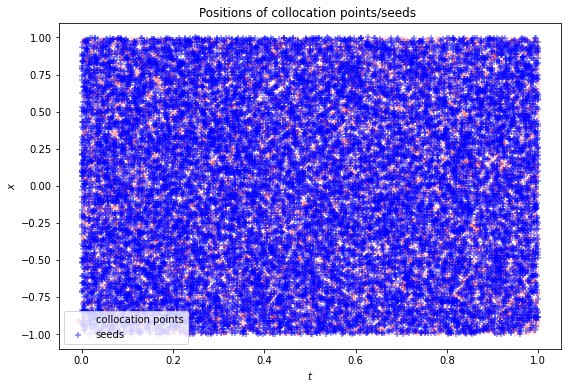

In [30]:
X_r, X_s = gen_train_data_v2(20_000, 20_000, False)
plot_train_data_v2(X_r, X_s)

In [31]:
class PINNSolver_alpha():
    def __init__(self, model, batch_size = 1_000):
        self.model = model

        # Initialize history of losses and global iteration counter
        self.hist = []
        self.epoch = 0
        self.batch_size = batch_size
        self.batch_history = []
        
    def get_r(self, x):
        
        t = x[:,0:1]
        x = x[:,1:2]
        
        with tf.GradientTape(persistent=True) as tape:
            # Watch variables representing t and x during this GradientTape
            tape.watch(t)
            tape.watch(x)
            
            # Compute current values u(t,x)
            u = self.model(tf.stack([t[:,0], x[:,0]], axis=1))
            u2 = tf.square(u)
            
            u_x = tape.gradient(u, x)
            
        u_t = tape.gradient(u, t)
        u_xx = tape.gradient(u_x, x)
        u2_x = tape.gradient(u2, x)

        del tape
        
        return u_t + u2_x/2. - viscosity * u_xx
    
    def loss_fn(self, x):
        
        # Compute phi_r
        r = self.get_r(x)
        phi_r = tf.divide(tf.square(r), 2e4*self.q_indices) #tf.reduce_mean(tf.square(r))
    
        # Initialize loss
        loss = tf.reduce_mean(phi_r)
        
        return loss
        
        
    def get_grad(self, x):
        
        with tf.GradientTape(persistent=True) as tape:
            # This tape is for derivatives with
            # respect to trainable variables
            tape.watch(self.model.trainable_variables)
            loss = self.loss_fn(x)
            
        g = tape.gradient(loss, self.model.trainable_variables)
        del tape
        
        return loss, g
    
    def solve_with_TFoptimizer(self, optimizer, X_r, X_seeds, alpha):
        """This method performs a gradient descent type optimization."""

        self.nb_uniform  = int(alpha * self.batch_size)
        self.nb_residual = int((1.0-alpha) * self.batch_size)

        # initilisation du KD_tree avec les seeds
        tree = KDTree(X_seeds)

        # localisation dans le KD_tree
        _, ii = tree.query(X_r, k=1)
        #X_rho = tf.gather(X_seeds, ii)
                    
        num_epochs = 10_000
        for epoch in range(num_epochs):

          # calcul de q_i
          J_seeds = get_residual(self.model, X_seeds) 
          J_rho = tf.gather(J_seeds, ii)
          sum_J_rho = tf.reduce_sum(J_rho**2)
          q = J_rho**2 / sum_J_rho
          qflat = q.numpy().flatten()
        
          for step in range(1):

              # tire les points 
              indices_uniform  = np.random.choice(len(X_r), size=self.nb_uniform, replace=False)
              indices_residual = np.random.choice(len(X_r), size=self.nb_residual, replace=False, p=qflat)
              indices = np.concatenate((indices_uniform, indices_residual), axis=None)
              batch = tf.gather(X_r, indices)
              self.q_indices = tf.gather(q, indices)

              # Perform gradient descent step
              loss, grad_theta = self.get_grad(batch)
              optimizer.apply_gradients(zip(grad_theta, self.model.trainable_variables))

          self.current_loss = loss.numpy()
          self.callback()
          if self.current_loss < 1e-5:
            break  
                          
    def callback(self, xr=None):
        
        if self.epoch % 100 == 0:
            print('\rEpoch {:06_}: loss = {:10.8e}'.format(self.epoch,self.current_loss), end='')
        self.hist.append(self.current_loss)
        self.epoch+=1
        
    def plot_loss_history(self, ax=None):

        if not ax:
            fig = plt.figure(figsize=(7,5))
            ax = fig.add_subplot(111)

        ax.semilogy(range(len(self.hist)), self.hist,'k-', label='Loss')
        ax.set_xlabel('$Iteration$')
        ax.set_ylabel('Loss')

        return ax

## Training

Epoch 09_900: loss = 3.78687882e+00
Training time: 1478.5753252506256 seconds


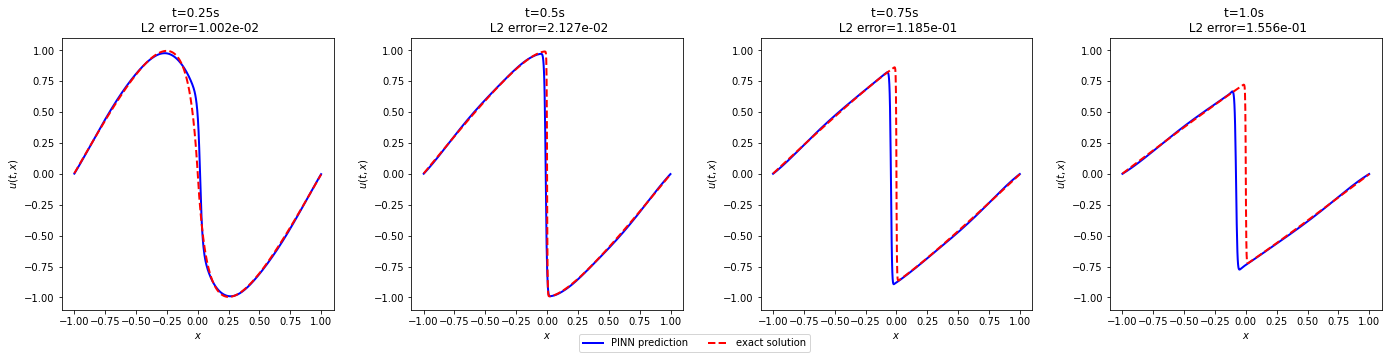

In [39]:
model = PhysicsInformedNN(lb, ub, num_hidden_layers=8, num_neurons_per_layer=64, activation='tanh')
solver = PINNSolver_alpha(model, batch_size = 5_000)

t0 = time()
try: 
  lr = tf.keras.optimizers.schedules.ExponentialDecay(
    1e-4,
    decay_steps=100,
    decay_rate=0.9,
    staircase=True)
  optim = tf.keras.optimizers.Adam(learning_rate=lr)
  solver.solve_with_TFoptimizer(optim, X_r, X_r, alpha = 0.)
except:
  pass

print('\nTraining time: {} seconds'.format(time()-t0))

all_times = [0.25, 0.5, 0.75, 1.0]
exact_solutions = []
N = 750

bg=EDP(N, viscosity.numpy() , u_0)
x = bg.cells[bg.begin:bg.end]


for i_t, end_time in enumerate(all_times):
  bg.init()
  sol=bg.solve(end_time)
  exact_solutions.append(sol[-1])

fig, ax = plt.subplots(1, 4, figsize=(24, 5))

for i_t, end_time in enumerate(all_times):

    exact_sol = exact_solutions[i_t]

    # solution en utilisant le PINN
    T, X = np.meshgrid(end_time, x)
    Xgrid = np.vstack([T.flatten(),X.flatten()]).T
    upred = model(tf.cast(Xgrid,DTYPE))
    upred = tf.reshape(upred, (1,N))[0].numpy()

    # affichage
    erreurL2 = (x[-1]-x[0])/N*np.sum((exact_sol-upred)**2)
    title = "t={}s \n L2 error={:5.3e}".format(end_time, erreurL2)
    ax[i_t].set_title(title)

    ax[i_t].plot(x, upred, 'b-', linewidth = 2, label="PINN prediction")
    ax[i_t].plot(x, exact_sol, 'r--', linewidth = 2, label="exact solution")

    ax[i_t].set_xlabel('$x$')
    ax[i_t].set_ylabel('$u(t,x)$')    
    ax[i_t].axis('square')
    ax[i_t].set_xlim([-1.1,1.1])
    ax[i_t].set_ylim([-1.1,1.1]);

handles, labels = ax[-1].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=4);

ValueError: Number of rows must be a positive integer, not 0

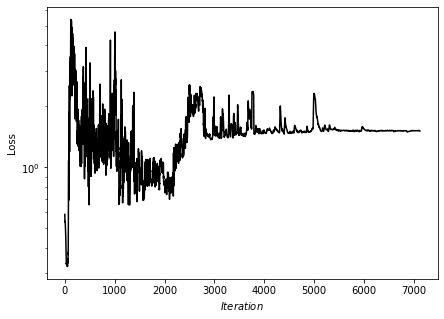

<Figure size 720x0 with 0 Axes>

In [38]:
solver.plot_loss_history()
plot_sampled_batch(solver.batch_history);